# Understanding loan cashflows and value

A lender advances EUR 100,000 today and receives interest and principal over the
next two years. A 6% coupon tells us how interest accrues. To understand the
investment, we also need to know when principal returns, which rates determine
future coupons, and how early repayment or default affects the income stream.

We will build that picture progressively. We start with a fixed-rate loan and
follow its monthly balance, then change the repayment structure and coupon.
From those cashflows we develop present value and the par lending rate, then
look at the lender's cost of funds and changes in market conditions. Finally,
we introduce borrower behaviour, credit losses, and exposure to market quotes.
Each extension uses the same starting agreement so its economic effect is visible.

The examples use the library's illustrative EUR market dated **24 February 2026**.
The lender's position is `Side.LongReceive`; amounts are in EUR, and rates are
entered as decimal fractions: `0.06` means 6%, and `0.01` means 100 basis points.

## The agreement and the market

Our loan pays monthly, with accrual periods running from the 24th of one month
to the 24th of the next. Interest uses Actual/360. If a payment falls on a
non-business day, the Following convention moves it to the next TARGET business
day; the accrual period keeps its original dates.

The quote files supply 3% ESTR deposits and 4% EURIBOR12m deposits. The pricing
context constructs an ESTR discount curve and a separate EURIBOR projection
curve from those quotes. ESTR discounting is also the collateral convention
chosen for this example. We will add the borrower CDS curve when we reach credit.
Entering `with pricing_context()` constructs the market used for that calculation.

A `Loan` records the payment agreement. Wrapping it in a `Trade` creates the
lender's position, whose future receipts have positive amounts.
`Side.PayShort` reverses the reported cashflow and value signs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import quantsupport as qs
from market_data import load_loan_market

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
valuation_date = "2026-02-24"
principal = 100_000.0
market = load_loan_market()
known_fixings = qs.FixingStore()

def pricing_context(scenarios=None, include_credit=False):
    return qs.PricingContext(
        market.quotes, market.curves,
        fixings=known_fixings,
        credit_curves=market.credit_curves if include_credit else [],
        csa_policy=market.csa_policy,
        scenarios=scenarios,
    )

contract_terms = dict(
    start_date=valuation_date,
    maturity_date="2028-02-24",
    notional=principal,
    currency=qs.Currency.EUR,
    discount_index=qs.MarketIndex.ESTR,
    payment_frequency=qs.Frequency.Monthly,
    day_counter=qs.DayCounter.Actual360,
    calendar="TARGET",
    business_day_convention=qs.BusinessDayConvention.Following,
    fixing_lag=2,
)
french = qs.LoanRepaymentStructure.french()
pricer = qs.LoanPricer()
requests = [qs.Request.Value, qs.Request.Cashflows, qs.Request.Sensitivities]

## How a monthly payment is formed

French amortization combines interest and principal in a level regular payment.
At the start of a period the borrower owes $B_{i-1}$. With annual coupon $r$ and
accrual fraction $\tau_i$, interest is $I_i=B_{i-1}r\tau_i$. The principal part
of payment $A$ is $Q_i=A-I_i$, leaving $B_i=B_{i-1}-Q_i$ outstanding.

For our first period, 24 February to 24 March, Actual/360 gives $28/360$ and
interest of $100{,}000\times6\%\times28/360=466.67$. A month with more accrual
days earns more interest on the same opening balance. The day-count convention
therefore matters even though payments occur monthly.

In [2]:
first_accrual_end = "2026-03-24"
accrual_comparison = []
for label, basis in [
    ("Actual/360", qs.DayCounter.Actual360),
    ("Actual/365", qs.DayCounter.Actual365),
    ("30/360", qs.DayCounter.Thirty360),
]:
    fraction = basis.year_fraction(valuation_date, first_accrual_end)
    accrual_comparison.append({
        "Accrual basis": label,
        "Year fraction": fraction,
        "First-period interest (EUR)": principal * 0.06 * fraction,
    })
display(pd.DataFrame(accrual_comparison).set_index("Accrual basis").style.format({
    "Year fraction": "{:.6f}", "First-period interest (EUR)": "{:,.2f}",
}))

,Year fraction,First-period interest (EUR)
Accrual basis,,
Actual/360,0.077778,466.67
Actual/365,0.076712,460.27
30/360,0.083333,500.00


The builder solves the level payment using every period's accrual fraction.
Writing $a_k=\prod_{j=1}^{k}(1+r\tau_j)^{-1}$, the payment that repays the loan
in $n$ periods is

$$A=\frac{B_0}{\sum_{k=1}^{n}a_k}.$$

These factors describe the contractual amortization calculation. The chosen
Actual/360 basis enters both interest and the principal schedule. The library
stores each opening coupon notional and each principal redemption when it
constructs the loan.

`Coupon.fixed(0.06)` supplies the coupon definition. The `coupons` list is
positional: its last entry continues through the remaining payment periods.
A single fixed coupon therefore covers the whole two-year term. The pricer's
cashflow request returns interest and principal as separate rows; we arrange
them by payment date to read the borrower's monthly payment.

In [3]:
fixed = qs.Loan(
    identifier="FIXED", coupons=[qs.Coupon.fixed(0.06)],
    repayment=french, **contract_terms,
)
with pricing_context() as context:
    fixed_result = pricer.evaluate(qs.Trade(fixed, valuation_date, qs.Side.LongReceive), context, requests)

fixed_payments = fixed_result.cashflows.pivot_table(
    index="payment_date", columns="type", values="amount", aggfunc="sum", fill_value=0,
).rename(columns={"FixedRateCoupon": "Interest", "Redemption": "Principal repaid"})
fixed_payments["Payment"] = fixed_payments["Interest"] + fixed_payments["Principal repaid"]
fixed_payments["Opening balance"] = principal - fixed_payments["Principal repaid"].cumsum().shift(fill_value=0)
fixed_payments["Closing balance"] = principal - fixed_payments["Principal repaid"].cumsum()
display(fixed_payments[["Opening balance", "Interest", "Principal repaid", "Payment", "Closing balance"]].head(6))

type,Opening balance,Interest,Principal repaid,Payment,Closing balance
payment_date,,,,,
2026-03-24,"100,000.00",466.67,"3,968.13","4,434.80","96,031.87"
2026-04-24,"96,031.87",496.16,"3,938.63","4,434.80","92,093.24"
2026-05-25,"92,093.24",460.47,"3,974.33","4,434.80","88,118.91"
2026-06-24,"88,118.91",455.28,"3,979.52","4,434.80","84,139.39"
2026-07-24,"84,139.39",420.70,"4,014.10","4,434.80","80,125.29"
2026-08-24,"80,125.29",413.98,"4,020.82","4,434.80","76,104.48"


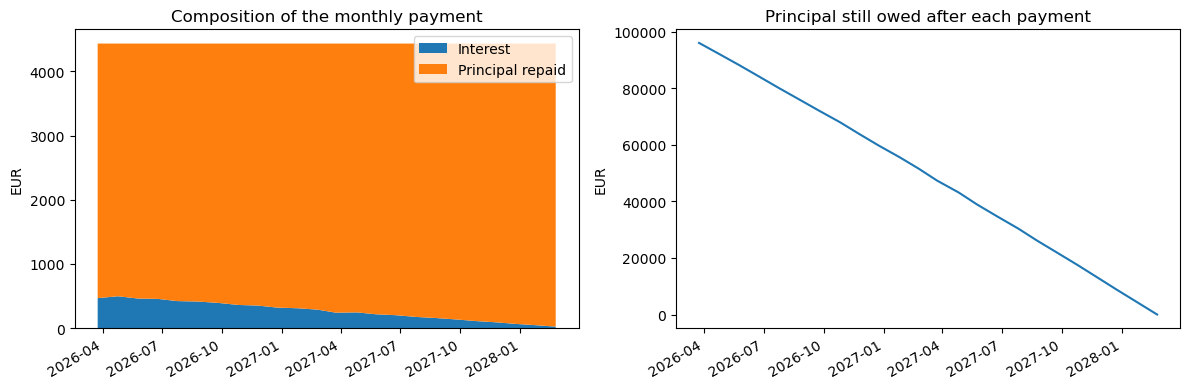

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
dates = pd.to_datetime(fixed_payments.index)
axes[0].stackplot(
    dates, fixed_payments["Interest"], fixed_payments["Principal repaid"],
    labels=["Interest", "Principal repaid"],
)
axes[0].set(title="Composition of the monthly payment", ylabel="EUR")
axes[0].legend(loc="upper right")
axes[1].plot(dates, fixed_payments["Closing balance"], color="tab:blue")
axes[1].set(title="Principal still owed after each payment", ylabel="EUR")
figure.autofmt_xdate()
figure.tight_layout()
plt.show()

The regular payment is EUR 4,434.80. Its first interest component is EUR 466.67,
leaving EUR 3,968.13 to repay principal. April's interest rises to EUR 496.16
despite the smaller balance because its accrual period has 31 days. Over the
full term, amortization reduces the interest component and increases the
principal repaid with each regular payment. The declining balance also reduces
the principal exposed to later rate movements and borrower default.

The current engine computes an unrounded schedule; the tables display the
resulting amounts to two decimal places.

## Choosing when principal returns

Repayment timing changes both borrower funding and lender exposure. A bullet
loan keeps the full EUR 100,000 outstanding until maturity, so each intervening
payment consists of interest. A balloon loan combines regular amortization with
a specified residual principal amount due at the end.

Here `balloon(0.25)` reserves EUR 25,000 of original principal for maturity.
For residual $L$, the regular payment becomes

$$A=\frac{B_0-L a_n}{\sum_{k=1}^{n}a_k}.$$

The final receipt includes the regular payment and the residual. We keep the 6%
coupon and market assumptions the same across structures to see how the timing
of principal affects monthly payments, total interest, and receipt value.

In [5]:
repayment_choices = {
    "French": fixed,
    "Bullet": qs.Loan(
        identifier="BULLET", coupons=[qs.Coupon.fixed(0.06)],
        repayment=qs.LoanRepaymentStructure.bullet(), **contract_terms,
    ),
    "25% balloon": qs.Loan(
        identifier="BALLOON", coupons=[qs.Coupon.fixed(0.06)],
        repayment=qs.LoanRepaymentStructure.balloon(0.25), **contract_terms,
    ),
}
repayment_comparison = []
with pricing_context() as context:
    for label, instrument in repayment_choices.items():
        result = pricer.evaluate(qs.Trade(instrument, valuation_date), context, ["Value", "Cashflows"])
        payments = result.cashflows.groupby("payment_date").amount.sum()
        interest = result.cashflows.loc[result.cashflows.type == "FixedRateCoupon", "amount"].sum()
        repayment_comparison.append({
            "Repayment": label,
            "First payment (EUR)": payments.iloc[0],
            "Final payment (EUR)": payments.iloc[-1],
            "Total interest (EUR)": interest,
            "Value of receipts (EUR)": result.price,
        })
display(pd.DataFrame(repayment_comparison).set_index("Repayment"))

,First payment (EUR),Final payment (EUR),Total interest (EUR),Value of receipts (EUR)
Repayment,,,,
French,"4,434.80","4,434.80","6,435.12","103,212.08"
Bullet,466.67,"100,516.67","12,166.67","106,062.43"
25% balloon,"3,452.80","28,452.80","7,867.30","103,924.32"


The bullet loan earns interest on the full principal for two years. Its smaller
interim payments come with a large final funding requirement for the borrower.
The 25% balloon lowers the regular payment to EUR 3,452.80, with a final
EUR 28,452.80 receipt that includes the EUR 25,000 residual. In this market,
the 6% coupon is above the rate needed to lend at par; retaining principal for
longer therefore raises the value of the lender's future interest income.
Credit exposure will also persist for longer on those outstanding balances.

## Floating interest, annual resets, and an introductory fixed period

A EURIBOR12m loan with a 1% spread earns an annual coupon equal to the applicable
EURIBOR fixing plus 100 basis points. Payment frequency and reset frequency
serve different purposes: this loan pays monthly, while the 12-month index resets
the reference rate once a year. Each of the following twelve monthly coupons
uses that observed rate.

The library takes the reset frequency and observation tenor from the index
metadata. The loan's two-business-day fixing lag places the first observation
on 20 February, before our valuation date. We supply that historical fixing as
4%. Later observations come from the EURIBOR projection curve. Interest accrues
over each monthly period using the loan's Actual/360 convention.

For amortization, we choose an initial all-in rate of 5%. That input determines
the agreed principal amounts. Subsequent fixings determine interest on those
balances, so a reset can change the total monthly payment.

In [6]:
floating = qs.Loan(
    identifier="FLOATING", coupons=[qs.Coupon.floating("EURIBOR12m", spread=0.01)],
    repayment=french, amortization_rate=0.05, **contract_terms,
)
observations = floating.coupon_fixing_requests()
for observation in observations.itertuples(index=False):
    if observation.fixing_date < valuation_date:
        known_fixings.add(observation.market_index, observation.fixing_date, 0.04)
display(observations.rename(columns={
    "fixing_date": "Observation date", "start_date": "Index period start",
    "end_date": "Index period end", "market_index": "Index",
}))

with pricing_context() as context:
    floating_result = pricer.evaluate(qs.Trade(floating, valuation_date), context, requests)
floating_coupons = floating_result.cashflows.loc[
    floating_result.cashflows.type == "FloatingRateCoupon",
    ["payment_date", "fixing", "accrual_period", "amount"],
].copy()
floating_coupons["All-in coupon (%)"] = (floating_coupons.fixing + 0.01) * 100
floating_coupons["EURIBOR fixing (%)"] = floating_coupons.fixing * 100
display(floating_coupons.iloc[[0, 1, 11, 12, -1]][
    ["payment_date", "EURIBOR fixing (%)", "All-in coupon (%)", "accrual_period", "amount"]
].rename(columns={
    "payment_date": "Payment date", "amount": "Interest (EUR)",
    "accrual_period": "Accrual fraction",
}).style.format({
    "Accrual fraction": "{:.6f}", "EURIBOR fixing (%)": "{:.4f}",
    "All-in coupon (%)": "{:.4f}", "Interest (EUR)": "{:,.2f}",
}))

,Index,Observation date,Index period start,Index period end
0,EURIBOR12m,2026-02-20,2026-02-24,2027-02-24
1,EURIBOR12m,2027-02-22,2027-02-24,2028-02-24


,Payment date,EURIBOR fixing (%),All-in coupon (%),Accrual fraction,Interest (EUR)
0,2026-03-24,4.0000,5.0000,0.077778,388.89
2,2026-04-24,4.0000,5.0000,0.086111,413.33
22,2027-02-24,4.0000,5.0000,0.086111,238.59
24,2027-03-24,3.8441,4.8441,0.077778,193.15
46,2028-02-24,3.8441,4.8441,0.086111,18.23


At the second reset, the forecast index is about 3.84%, giving an all-in coupon
of about 4.84%. For EURIBOR's simple-rate convention, the forward observation
comes from the projection curve over the full index period:

$$F(t,T)=\frac{P_L(0,t)/P_L(0,T)-1}{\tau_L(t,T)}.$$

Here $P_L$ contains EURIBOR projection discount factors and $\tau_L$ is the
index's Actual/360 accrual fraction over twelve months. The deposit quotes
encode cumulative returns to their maturities; the ratio extracts the return
for the future year. This is why the second-year forward can differ from the 4%
deposit inputs. Each monthly coupon then applies the resolved annual index rate
plus the loan spread to that month's accrual fraction.

An introductory fixed period changes the coupon schedule. In the next loan,
the first twelve monthly periods earn 4%; the remaining periods earn EURIBOR12m
plus 1%. The coupon list ends with the floating definition, which continues to
maturity. The first fixed coupon supplies the initial amortization rate, giving
this agreement a principal schedule based on 4%.

This is the library's convention for mixed and stepped loans: coupon definitions
can change from period to period while the initial principal schedule continues.
The total payment after the switch reflects both the agreed principal amount
and interest under the new coupon.

,6% fixed,EURIBOR12m + 1%,"4% for one year, then EURIBOR12m + 1%"
payment_date,,,
2026-03-24,"4,434.80","4,389.41","4,344.30"
2027-02-24,"4,434.80","4,389.41","4,344.30"
2027-03-24,"4,434.80","4,383.19","4,377.79"
2028-02-24,"4,434.80","4,388.82","4,347.45"


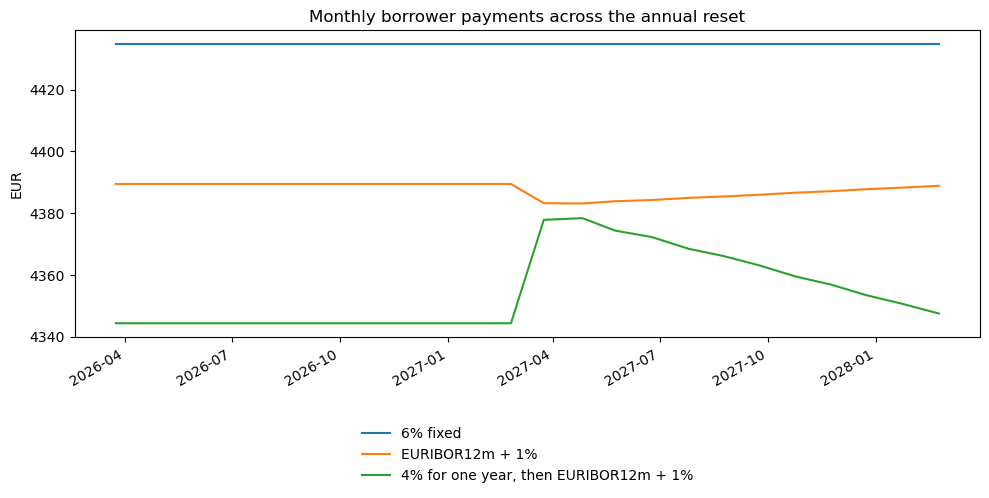

In [7]:
mixed = qs.Loan(
    identifier="INTRODUCTORY-FIXED",
    coupons=[qs.Coupon.fixed(0.04)] * 12 + [qs.Coupon.floating("EURIBOR12m", spread=0.01)],
    repayment=french, **contract_terms,
)
with pricing_context() as context:
    mixed_result = pricer.evaluate(qs.Trade(mixed, valuation_date), context, requests)

payment_paths = pd.DataFrame({
    "6% fixed": fixed_result.cashflows.groupby("payment_date").amount.sum(),
    "EURIBOR12m + 1%": floating_result.cashflows.groupby("payment_date").amount.sum(),
    "4% for one year, then EURIBOR12m + 1%": mixed_result.cashflows.groupby("payment_date").amount.sum(),
})
display(payment_paths.iloc[[0, 11, 12, -1]])
figure, axis = plt.subplots(figsize=(10, 5.2))
for label in payment_paths:
    axis.plot(pd.to_datetime(payment_paths.index), payment_paths[label], label=label)
axis.set(title="Monthly borrower payments across the annual reset", ylabel="EUR")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
figure.autofmt_xdate()
figure.tight_layout()
plt.show()

Floating coupons can also have an all-in floor and cap. For a 2% floor and
4.5% cap, the coupon is $\min(4.5\%,\max(2\%,L+1\%))$, where $L$ is the index
observation. The initial 4% fixing would otherwise produce a 5% coupon, so the
cap limits the first year's interest income.

`LoanPricer` applies these bounds to the resolved index observations. The result
shows the projected cash payments under those rates. A valuation of the embedded
interest-rate option's time value would additionally require a volatility model.

In [8]:
bounded = qs.Loan(
    identifier="FLOOR-AND-CAP",
    coupons=[qs.Coupon.floating("EURIBOR12m", spread=0.01, floor=0.02, cap=0.045)],
    repayment=french, amortization_rate=0.05, **contract_terms,
)
with pricing_context() as context:
    bounded_result = pricer.evaluate(qs.Trade(bounded, valuation_date), context, ["Value", "Cashflows"])
display(pd.DataFrame({
    "Unbounded floating": floating_result.cashflows.groupby("payment_date").amount.sum(),
    "2% floor, 4.5% cap": bounded_result.cashflows.groupby("payment_date").amount.sum(),
}).iloc[[0, 11, 12, -1]])

,Unbounded floating,"2% floor, 4.5% cap"
payment_date,,
2026-03-24,"4,389.41","4,350.52"
2027-02-24,"4,389.41","4,365.55"
2027-03-24,"4,383.19","4,369.47"
2028-02-24,"4,388.82","4,387.53"


## Present value and the coupon that lends at par

A loan's value depends on the timing of its income. For discount factors
$D(0,t_i)$ and future receipts $C_i$, the lender's receipt value is

$$V_{\mathrm{receipts}}=\sum_i D(0,t_i)\,\mathbb{E}[C_i].$$

The `price` returned by the loan pricer is this value of future receipts. At
origination the lender also advances EUR 100,000, giving an initial net value of
$V_{\mathrm{receipts}}-100{,}000$. Payment dates strictly after the valuation
date enter the receipt value. Our example starts on the valuation date, so the
full advance occurs today.

With a 6% fixed coupon and the selected ESTR discount curve, the loan trades at a
premium to its original principal. The nominal interest total and present value
answer different financial questions: the former measures currency received
over the life of the loan, while the latter accounts for when it arrives.

In [9]:
origination_values = []
for label, result in [
    ("6% fixed", fixed_result),
    ("EURIBOR12m + 1%", floating_result),
    ("Introductory fixed", mixed_result),
]:
    origination_values.append({
        "Agreement": label,
        "Value of receipts (EUR)": result.price,
        "Advance today (EUR)": principal,
        "Lender value after advance (EUR)": result.price - principal,
    })
display(pd.DataFrame(origination_values).set_index("Agreement"))

,Value of receipts (EUR),Advance today (EUR),Lender value after advance (EUR)
Agreement,,,
6% fixed,"103,212.08","100,000.00","3,212.08"
EURIBOR12m + 1%,"102,113.62","100,000.00","2,113.62"
Introductory fixed,"101,332.62","100,000.00","1,332.62"


`FairRate` solves the coupon or floating spread that makes the value of receipts
equal to the value of the advance. There are two useful ways to pose that problem.
An existing principal schedule can be retained while changing its coupon. A new
loan can instead have its amortization recalculated for each candidate rate.

`rebuild_amortization_for_fair_rate` selects between those two assumptions.
With `False`, the solver keeps the agreed principal amounts. With `True`, it
rebuilds the French payment using the trial fixed coupon, or the first observed
index rate plus the trial floating spread. The settings can give slightly
different par rates because they change the timing of principal repayments.
The library supports this solve at or before origination for uniform fixed or
unbounded floating coupons.

In [10]:
fair_rate_comparison = []
with pricing_context() as context:
    for rebuild, schedule in [
        (False, "Keep the agreed principal schedule"),
        (True, "Rebuild principal at the trial rate"),
    ]:
        fair_pricer = qs.LoanPricer(rebuild_amortization_for_fair_rate=rebuild)
        fixed_fair = fair_pricer.evaluate(
            qs.Trade(fixed, valuation_date), context, [qs.Request.FairRate],
        ).fair_rate
        floating_fair = fair_pricer.evaluate(
            qs.Trade(floating, valuation_date), context, [qs.Request.FairRate],
        ).fair_rate
        fair_rate_comparison.append({
            "Principal assumption": schedule,
            "Par fixed coupon (%)": fixed_fair * 100,
            "Par EURIBOR spread (bp)": floating_fair * 10_000,
        })
display(pd.DataFrame(fair_rate_comparison).set_index("Principal assumption").style.format("{:,.6f}"))

,Par fixed coupon (%),Par EURIBOR spread (bp)
Principal assumption,,
Keep the agreed principal schedule,2.939535,-102.010732
Rebuild principal at the trial rate,2.939790,-102.020845


In this illustrative market, the EURIBOR projection curve produces a higher
benchmark coupon than the ESTR-discounted par lending rate requires. The par
floating spread is consequently negative. It is the adjustment to the benchmark
needed under these particular cashflow and discount assumptions. The fixed
solution is an annual coupon; the floating solution is a margin added to EURIBOR.

## Valuing the loan against the lender's cost of funds

A lender funding an asset at EURIBOR plus a treasury spread needs the loan's
income to cover both components. We can express that funding hurdle as a discount
curve and ask what the agreed receipts are worth on that basis. This also gives
us the coupon or lending margin required to cover funding at origination.

We use the existing EURIBOR12m curve as the benchmark and introduce a separate
funding spread term structure. Its continuously compounded zero spreads rise
from **50 bp today to 75 bp at one year, 100 bp at two years, and 125 bp at three
years**, with linear interpolation and Actual/360 time. These are illustrative
treasury assumptions; the spread is charged over the EURIBOR benchmark.

For spread $s(T)$ and year fraction $\tau(0,T)$, the composite curve has

$$D_{\mathrm{funding}}(0,T)
  =D_{\mathrm{EURIBOR}}(0,T)\,D_{\mathrm{spread}}(0,T)
  =D_{\mathrm{EURIBOR}}(0,T)\,e^{-s(T)\tau(0,T)}.$$

Equivalently, the continuously compounded zero rate is
$z_{\mathrm{funding}}(T)=z_{\mathrm{EURIBOR}}(T)+s(T)$. The EURIBOR zero rate here
is obtained from its discount factor on the same time basis. This preserves the
compounding conventions of the original deposit quotes.

`add_zero_curve` registers the spread curve and `add_composite_curve` combines
its discount factors with the benchmark. A `FixedIncomeDiscountPolicy` then
selects the funding curve for `LoanPricer`. The same loan agreements and pricing
requests produce the funding values below.

In [11]:
from contextlib import contextmanager

funding_spread_index = qs.MarketIndex.other("FUNDINGSPREAD")
cost_of_funds_index = qs.MarketIndex.other("COSTOFFUNDS")
funding_tenors = ["0D", "1Y", "2Y", "3Y"]
funding_spreads = [0.0050, 0.0075, 0.0100, 0.0125]
display(pd.DataFrame({
    "Tenor": funding_tenors,
    "Continuous zero funding spread (bp)": [rate * 10_000 for rate in funding_spreads],
}).set_index("Tenor"))

@contextmanager
def funding_context(scenarios=None, funding_shift_bp=0):
    with pricing_context(scenarios=scenarios) as context:
        spread_curve = qs.TenorBasedZeroRateTermStructure(
            valuation_date, funding_tenors,
            [rate + funding_shift_bp / 10_000 for rate in funding_spreads],
            day_counter=qs.DayCounter.Actual360,
            compounding=qs.Compounding.Continuous,
            interpolator="Linear",
        )
        context.add_zero_curve(funding_spread_index, spread_curve)
        context.add_composite_curve(
            cost_of_funds_index, qs.MarketIndex.EURIBOR12m, funding_spread_index,
        )
        yield context

funding_policy = qs.FixedIncomeDiscountPolicy(
    {qs.Currency.EUR: cost_of_funds_index}, prefer_instrument_index=False,
)
funding_pricer = qs.LoanPricer(discount_policy=funding_policy)
benchmark_pricer = qs.LoanPricer(discount_policy=qs.FixedIncomeDiscountPolicy(
    {qs.Currency.EUR: qs.MarketIndex.EURIBOR12m}, prefer_instrument_index=False,
))

funding_values = []
funding_base_results = {}
with funding_context() as context:
    for label, instrument in [("6% fixed", fixed), ("EURIBOR12m + 1%", floating)]:
        for discount_basis, selected_pricer in [
            ("ESTR", pricer),
            ("EURIBOR12m", benchmark_pricer),
            ("EURIBOR12m + funding spread", funding_pricer),
        ]:
            result = selected_pricer.evaluate(
                qs.Trade(instrument, valuation_date), context,
                [qs.Request.Value, qs.Request.FairRate],
            )
            if discount_basis == "EURIBOR12m + funding spread":
                funding_base_results[label] = result
            funding_values.append({
                "Loan": label,
                "Discount basis": discount_basis,
                "Value of receipts (EUR)": result.price,
                "Value after advance (EUR)": result.price - principal,
                "Par fixed coupon (%)": result.fair_rate * 100 if instrument is fixed else None,
                "Par EURIBOR margin (bp)": result.fair_rate * 10_000 if instrument is floating else None,
            })
display(pd.DataFrame(funding_values).set_index(["Loan", "Discount basis"]).style.format(
    "{:,.2f}", na_rep="—",
))

,Continuous zero funding spread (bp)
Tenor,
0D,50.00
1Y,75.00
2Y,100.00
3Y,125.00


The fixed loan's receipt value falls from EUR 103,212.08 under ESTR discounting
to EUR 102,196.33 on EURIBOR and EUR 101,311.42 after the funding spread. Its
funding-based par coupon is about 4.73%, leaving a positive origination value
of EUR 1,311.42 at the agreed 6% coupon.

For the floating loan, the funding-based par margin is 77.41 bp. The agreed
100 bp margin produces an origination value of EUR 233.46 after the advance.
That smaller cushion makes its value more vulnerable to a widening in the
lender's funding spread.

These values describe the funding hurdle for the promised receipts. The
prepayment and borrower recovery sections below will introduce uncertainty in
those receipts. The fair-rate calculations here retain each agreed principal
schedule, using the default `rebuild_amortization_for_fair_rate=False`.

## Scenarios: benchmark rates and funding pressure

Two changes matter to the funded lender. A move in EURIBOR changes the benchmark
component of discounting and the floating coupons whose fixings are still in
the future. A wider treasury spread increases the funding hurdle for every
remaining receipt. We can examine each channel, then combine them in a funding
stress.

`Scenario("EURIBOR12m", shift, Absolute)` selects the EURIBOR quote pillars.
A shift of `0.01` adds 100 bp to each quote, and the context bootstraps a fresh
benchmark curve. These are parallel **quote** shocks; the calibrated zero and
forward rates move according to the curve construction. The funding spread
curve is an explicit zero-rate input, so a funding shock adds directly to each
of its spread pillars before composition.

Each row below is a separate, fully repriced market on the same valuation date.
We keep the loan contracts and known fixings. In particular, the floating loan's
first annual EURIBOR fixing remains 4%, and its existing principal amounts stay
in place. Profit or loss is the change in the funding-discounted receipt value
relative to the base market.

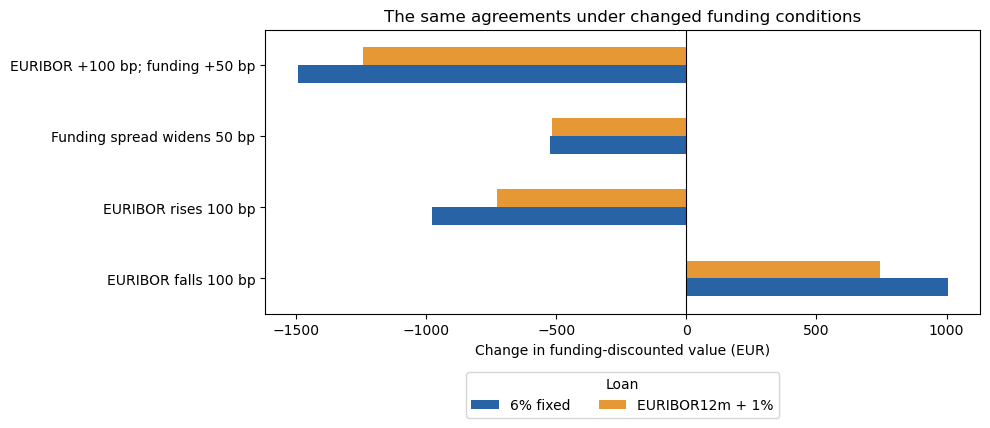

In [12]:
market_scenarios = [
    ("Base market", 0, 0),
    ("EURIBOR falls 100 bp", -100, 0),
    ("EURIBOR rises 100 bp", 100, 0),
    ("Funding spread widens 50 bp", 0, 50),
    ("EURIBOR +100 bp; funding +50 bp", 100, 50),
]
scenario_values = []
for scenario_name, benchmark_shift_bp, funding_shift_bp in market_scenarios:
    quote_shocks = [qs.Scenario(
        "EURIBOR12m", benchmark_shift_bp / 10_000, qs.ScenarioType.Absolute,
    )] if benchmark_shift_bp else []
    with funding_context(quote_shocks, funding_shift_bp) as context:
        for label, instrument in [("6% fixed", fixed), ("EURIBOR12m + 1%", floating)]:
            result = funding_pricer.evaluate(
                qs.Trade(instrument, valuation_date), context,
                [qs.Request.Value, qs.Request.Cashflows],
            )
            coupons = result.cashflows.loc[
                result.cashflows.type.isin(["FixedRateCoupon", "FloatingRateCoupon"])
            ]
            scenario_values.append({
                "Scenario": scenario_name,
                "Loan": label,
                "EURIBOR quote shift (bp)": benchmark_shift_bp,
                "Funding spread shift (bp)": funding_shift_bp,
                "Projected interest (EUR)": coupons.amount.sum(),
                "Funding value (EUR)": result.price,
                "Profit or loss (EUR)": result.price - funding_base_results[label].price,
            })
scenario_table = pd.DataFrame(scenario_values)
display(scenario_table.set_index(["Scenario", "Loan"]).style.format("{:,.2f}"))

scenario_pnl = scenario_table.pivot(
    index="Scenario", columns="Loan", values="Profit or loss (EUR)",
).reindex([name for name, _, _ in market_scenarios][1:])
ax = scenario_pnl.plot.barh(figsize=(10, 4.5), color=["#2864a5", "#e69834"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Change in funding-discounted value (EUR)")
ax.set_ylabel("")
ax.set_title("The same agreements under changed funding conditions")
ax.legend(title="Loan", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.show()

The fixed loan keeps its EUR 6,435.12 of contractual interest in every scenario.
Higher benchmark rates or funding spreads lower its value because those receipts
are discounted more heavily. The floating loan gains future coupon income when
EURIBOR rises, which offsets part of the increased benchmark funding cost. Its
known first-year fixing limits that offset over this two-year term.

A 50 bp funding-spread widening leaves both loans' projected interest unchanged
and lowers their receipt values by EUR 523.35 and EUR 517.71 respectively. The
floating loan's value falls to EUR 99,715.76, taking its value after the initial
advance below zero. With EURIBOR also 100 bp higher, its projected interest rises
to EUR 5,559.55, but the higher funding hurdle brings receipt value down to
EUR 98,992.15.
The separate refinancing example below adds the borrower's early-repayment
response to changes in the benchmark.

## Early repayment and the life of the income stream

A borrower who prepays returns principal earlier and reduces the interest the
lender will receive later. Conditional prepayment rate, or CPR, expresses the
annual rate of early principal repayment on the balance that remains after
scheduled amortization.

For a regular monthly interval, the library converts annual CPR $c$ to a monthly
conditional probability

$$\pi=1-(1-c)^{1/12}.$$

With 25% annual CPR, this is about 2.37% per month. The pricer first pays scheduled
principal $Q_i$, then applies $\pi_i$ to the remaining balance. Future scheduled
interest and principal are weighted by the fraction expected to remain. This
produces an expected balance path while retaining the agreed contractual terms.

The prepayment interval has its own clock: a full monthly interval uses $1/12$
year, and partial or irregular intervals use Actual/365. Coupon interest in our
agreement continues to use Actual/360.

,Expected principal life (years),Expected interest (EUR),Value of receipts (EUR)
Prepayment assumption,,,
Scheduled payments only,1.06,"6,435.12","103,212.08"
12% annual CPR,0.98,"5,933.81","102,962.37"
25% annual CPR,0.89,"5,389.08","102,691.03"


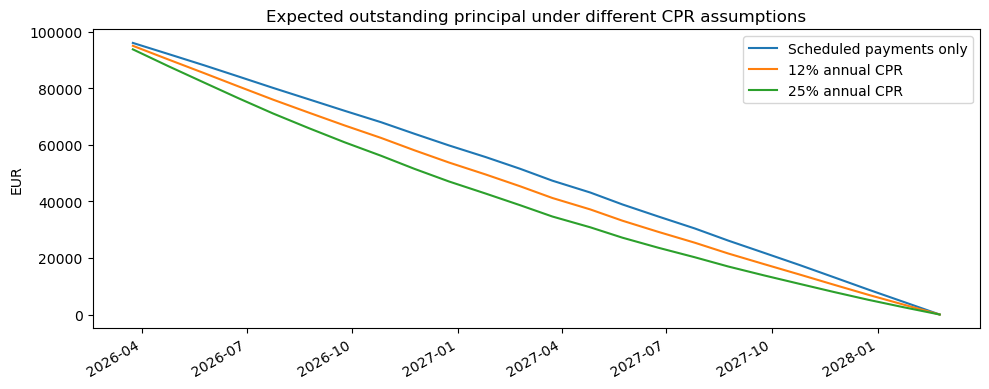

In [13]:
prepayment_models = {
    "Scheduled payments only": qs.PrepaymentModelConfiguration.no_prepayment(),
    "12% annual CPR": qs.PrepaymentModelConfiguration.constant_annual_cpr(0.12),
    "25% annual CPR": qs.PrepaymentModelConfiguration.constant_annual_cpr(0.25),
}
prepayment_results = {}
prepayment_comparison = []
with pricing_context() as context:
    for label, model in prepayment_models.items():
        instrument = qs.Loan(
            identifier=label, coupons=[qs.Coupon.fixed(0.06)],
            repayment=french, prepayment=model, **contract_terms,
        )
        result = pricer.evaluate(qs.Trade(instrument, valuation_date), context, requests)
        prepayment_results[label] = result
        principal_receipts = result.cashflows.loc[result.cashflows.type == "Redemption"]
        average_life = sum(
            row.amount * qs.DayCounter.Actual365.year_fraction(valuation_date, row.payment_date)
            for row in principal_receipts.itertuples(index=False)
        ) / principal
        prepayment_comparison.append({
            "Prepayment assumption": label,
            "Expected principal life (years)": average_life,
            "Expected interest (EUR)": result.cashflows.loc[result.cashflows.type == "FixedRateCoupon", "amount"].sum(),
            "Value of receipts (EUR)": result.price,
        })
display(pd.DataFrame(prepayment_comparison).set_index("Prepayment assumption"))

figure, axis = plt.subplots(figsize=(10, 4))
for label, result in prepayment_results.items():
    principal_receipts = result.cashflows.loc[result.cashflows.type == "Redemption"].groupby("payment_date").amount.sum()
    balance = principal - principal_receipts.cumsum()
    axis.plot(pd.to_datetime(balance.index), balance, label=label)
axis.set(title="Expected outstanding principal under different CPR assumptions", ylabel="EUR")
axis.legend()
figure.autofmt_xdate()
figure.tight_layout()
plt.show()

The expected principal life is the average time at which each euro of principal
returns, weighted by its repayment amount. At 25% CPR it falls from about 1.06
to 0.89 years, while expected interest falls from EUR 6,435.12 to EUR 5,389.08.
For this premium fixed-rate loan, faster repayment also reduces receipt value:
the lender receives principal sooner but loses some of the attractive 6% income.

The library also supports a dated CPR curve through
`PrepaymentModelConfiguration.dated_annual_cpr`. It uses the latest annual CPR
whose effective date has been reached at the start of the interval, zero before
the first date, and the last supplied rate for subsequent intervals. This can
represent a seasoning pattern or an expected change in borrower behaviour.

### Linking prepayment to a refinancing incentive

A constant CPR gives a chosen repayment speed. A refinancing model makes that
speed respond to rates. The library's incentive specification uses

$$c=\min\left(c_{\max},\ c_{\mathrm{base}}+
\alpha\max(r_{\mathrm{coupon}}-r_{\mathrm{benchmark}},0)\right).$$

We choose base CPR of 2%, an incentive multiplier of 4, and a 40% annual cap.
A one-percentage-point increase in a positive coupon-minus-benchmark gap adds
four percentage points to annual CPR, until the cap binds. The configured
EURIBOR12m index supplies the refinancing benchmark. This benchmark contains
the index rate; a borrower's replacement lending spread, fees, and transaction
costs would require a richer incentive specification.

The following scenarios move the EURIBOR deposit quotes by 100 basis points in
either direction while retaining the ESTR discount inputs. They show how the
prepayment assumption transmits a benchmark-rate move to a fixed-rate loan's
future interest income.

In [14]:
refinancing_loan = qs.Loan(
    identifier="REFINANCING", coupons=[qs.Coupon.fixed(0.06)], repayment=french,
    prepayment=qs.PrepaymentModelConfiguration.refinancing_incentive(
        base_cpr=0.02, incentive_multiplier=4.0, maximum_cpr=0.40,
    ),
    **contract_terms,
)
refinancing_pricer = qs.LoanPricer(refinancing_benchmark_index="EURIBOR12m")
with pricing_context() as context:
    refinancing_result = refinancing_pricer.evaluate(
        qs.Trade(refinancing_loan, valuation_date), context, requests,
    )

refinancing_scenarios = []
for shift_bp in [-100, 0, 100]:
    scenarios = [
        qs.Scenario(f"FixedRateDeposit_EUR_EURIBOR12m_{tenor}", shift_bp / 10_000, qs.ScenarioType.Absolute)
        for tenor in ["1D", "1Y", "2Y", "3Y"]
    ]
    with pricing_context(scenarios=scenarios) as context:
        result = refinancing_pricer.evaluate(
            qs.Trade(refinancing_loan, valuation_date), context, ["Value", "Cashflows"],
        )
    refinancing_scenarios.append({
        "EURIBOR quote shift (bp)": shift_bp,
        "Expected prepayment (EUR)": result.cashflows.loc[result.cashflows.leg_index == 1, "amount"].sum(),
        "Expected interest (EUR)": result.cashflows.loc[result.cashflows.type == "FixedRateCoupon", "amount"].sum(),
        "Value of receipts (EUR)": result.price,
        "Value change (EUR)": result.price - refinancing_result.price,
    })
display(pd.DataFrame(refinancing_scenarios).set_index("EURIBOR quote shift (bp)"))

,Expected prepayment (EUR),Expected interest (EUR),Value of receipts (EUR),Value change (EUR)
EURIBOR quote shift (bp),,,,
-100,"13,586.75","5,843.64","102,917.46",-80.77
0,"9,979.79","6,005.79","102,998.22",0.00
100,"6,370.23","6,166.39","103,078.22",80.00


A 100-basis-point fall in these benchmark quotes raises expected early repayment
from EUR 9,979.79 to EUR 13,586.75. The lender gives up more future income and
receipt value falls by EUR 80.77. A rising benchmark reduces that incentive
and allows the income stream to persist. The prepayment model therefore gives
a fixed-coupon loan an additional exposure to the refinancing benchmark.

## Borrower default and recovery

So far the borrower has met every payment that remained outstanding. We now
attach the `BORROWER` survival curve, constructed from the sample CDS quotes,
and assume recovery of 40% of opening principal upon default. The credit-curve
configuration uses the same recovery assumption when interpreting those quotes.

Let $S_i$ be survival to payment date $t_i$, conditional on survival at valuation.
For a period with interest $I_i$ and principal $Q_i$, the library's expected
receipt, before discounting, is

$$S_i(I_i+Q_i)+R B_{i-1}(S_{i-1}-S_i).$$

Survival weights the scheduled receipt. The second term adds recovery against
the probability of default during the interval. Recovery is paid at the
period's payment date using opening principal; this gives the library a discrete
approximation to the timing of default recoveries.

The cashflow report identifies scheduled receipts with `leg_index=0`, prepayment
with `leg_index=1`, and recovery with `leg_index=2`. Recovery uses the existing
`ConstantAmount` cashflow type. Here the loan has scheduled amortization and
borrower credit risk.

In [15]:
credit_loan = qs.Loan(
    identifier="BORROWER-CREDIT", coupons=[qs.Coupon.fixed(0.06)], repayment=french,
    credit_index=qs.MarketIndex.credit("BORROWER"), recovery=0.40,
    **contract_terms,
)
with pricing_context(include_credit=True) as context:
    credit_result = pricer.evaluate(qs.Trade(credit_loan, valuation_date), context, requests)

credit_payments = credit_result.cashflows.pivot_table(
    index="payment_date", columns="type", values="amount", aggfunc="sum", fill_value=0,
).rename(columns={
    "FixedRateCoupon": "Expected interest",
    "Redemption": "Expected scheduled principal",
    "ConstantAmount": "Expected recovery",
})
display(credit_payments.head(6))
display(pd.DataFrame([
    {"Borrower assumption": "All scheduled payments received", "Value of receipts (EUR)": fixed_result.price},
    {"Borrower assumption": "CDS survival curve, 40% recovery", "Value of receipts (EUR)": credit_result.price},
]).set_index("Borrower assumption"))

type,Expected recovery,Expected interest,Expected scheduled principal
payment_date,,,
2026-03-24,51.82,466.06,"3,962.99"
2026-04-24,55.02,494.81,"3,927.89"
2026-05-25,52.69,458.55,"3,957.81"
2026-06-24,48.72,452.76,"3,957.47"
2026-07-24,46.45,417.79,"3,986.32"
2026-08-24,45.65,410.53,"3,987.26"


,Value of receipts (EUR)
Borrower assumption,
All scheduled payments received,"103,212.08"
"CDS survival curve, 40% recovery","102,046.69"


The declining contractual balance reduces the principal exposed to default as
the loan seasons. Expected recovery replaces part of the income lost when the
borrower defaults, and the receipt value falls from EUR 103,212.08 to EUR 102,046.69
under the example's credit assumptions. Applying the same credit assumptions
to a bullet loan would retain exposure to the original principal until maturity.

## Reading the market-quote exposure

The price sensitivities describe which market inputs drive the value of the
income stream. Each `value` is a derivative $\partial V/\partial q$ with respect
to a labelled quote. Rate quotes are decimal fractions, so multiplying by
$0.0001$ gives the approximate EUR price change for a one-basis-point increase.

We compare the original fixed loan, the floating loan, and the fixed loan with
refinancing-sensitive prepayment. The table keeps the market-quote labels so we
can distinguish discounting exposure from the EURIBOR benchmark exposure.

In [16]:
quote_exposures = []
for label, result in [
    ("6% fixed", fixed_result),
    ("Floating", floating_result),
    ("Fixed with refinancing prepayment", refinancing_result),
]:
    risk = result.sensitivities.copy()
    risk["Loan"] = label
    risk["EUR change for +1bp"] = risk.value * 0.0001
    quote_exposures.append(risk[["pillar", "Loan", "EUR change for +1bp"]])

risk_table = pd.concat(quote_exposures).pivot_table(
    index="pillar", columns="Loan", values="EUR change for +1bp", aggfunc="sum", fill_value=0,
)
display(risk_table.style.format("{:+,.4f}"))

Loan,6% fixed,Fixed with refinancing prepayment,Floating
pillar,,,
FixedRateDeposit_EUR_ESTR_1D,-0.0068,-0.0077,-0.0067
FixedRateDeposit_EUR_ESTR_1Y,-5.0751,-5.0945,-5.0206
FixedRateDeposit_EUR_ESTR_2Y,-5.2154,-4.5187,-5.1588
FixedRateDeposit_EUR_ESTR_3Y,+0.0000,+0.0000,+0.0000
FixedRateDeposit_EUR_EURIBOR12m_1D,+0.0000,-0.0011,+0.0000
FixedRateDeposit_EUR_EURIBOR12m_1Y,+0.0000,+0.1500,-2.6988
FixedRateDeposit_EUR_EURIBOR12m_2Y,+0.0000,+0.5983,+5.1952
FixedRateDeposit_EUR_EURIBOR12m_3Y,+0.0000,+0.0566,+0.0000


The fixed loan's exposure comes from discounting its agreed receipts. The
floating loan also responds to the EURIBOR quotes used to project its future
reset. Its first annual fixing is already known, so that year's coupon income
has been set; the future reset supplies the remaining projection exposure.

The refinancing-sensitive fixed loan adds a different EURIBOR channel. Higher
benchmark rates reduce expected prepayment and preserve some of its above-market
coupon income. Its quote exposure reflects that change in repayment behaviour,
alongside the value effect of the discount curve.